# Social Media Addiction with DataDriven Insights

### Tasks & Guidelines:
#### 1. Data Understanding & Cleaning
#### ● Load the dataset
#### ● Handle missing values, if any
#### ● Perform appropriate data type conversions if required. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the dataset
df = pd.read_csv(r"D:\Adda 247 DA data\Python\mini Project\Students Social Media Addiction (1).csv")
df.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    705 non-null    int64  
 1   Age                           705 non-null    int64  
 2   Gender                        705 non-null    object 
 3   Academic_Level                705 non-null    object 
 4   Country                       705 non-null    object 
 5   Avg_Daily_Usage_Hours         705 non-null    float64
 6   Most_Used_Platform            705 non-null    object 
 7   Affects_Academic_Performance  705 non-null    object 
 8   Sleep_Hours_Per_Night         705 non-null    float64
 9   Mental_Health_Score           705 non-null    int64  
 10  Relationship_Status           705 non-null    object 
 11  Conflicts_Over_Social_Media   705 non-null    int64  
 12  Addicted_Score                705 non-null    int64  
dtypes: fl

In [5]:
# Handle missing values, if any
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Country                         0
Avg_Daily_Usage_Hours           0
Most_Used_Platform              0
Affects_Academic_Performance    0
Sleep_Hours_Per_Night           0
Mental_Health_Score             0
Relationship_Status             0
Conflicts_Over_Social_Media     0
Addicted_Score                  0
dtype: int64


In [7]:
# Perform appropriate data type conversions if required.
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


Total missing values: 0
Duplicate rows: 0


### 2. Exploratory Data Analysis (EDA)
#### ● Understand relationships between:
 #####   ○ Age, Gender, Daily Usage (in hours)
 #####   ○ Sleep patterns, Academic performance, Social interaction
#### ● Analyze how addiction varies across demographics

In [11]:
num_cols = ['Age','Avg_Daily_Usage_Hours','Sleep_Hours_Per_Night',
            'Mental_Health_Score','Conflicts_Over_Social_Media','Addicted_Score']
corr = df[num_cols].corr()
corr.round(2)

,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
Age,1.00,-0.11,0.13,0.16,-0.18,-0.17
Avg_Daily_Usage_Hours,-0.11,1.00,-0.79,-0.80,0.80,0.83
Sleep_Hours_Per_Night,0.13,-0.79,1.00,0.71,-0.68,-0.76
Mental_Health_Score,0.16,-0.80,0.71,1.00,-0.89,-0.95
Conflicts_Over_Social_Media,-0.18,0.80,-0.68,-0.89,1.00,0.93
Addicted_Score,-0.17,0.83,-0.76,-0.95,0.93,1.00


In [13]:
print("Avg usage by gender:\n", df.groupby('Gender', observed=True)['Avg_Daily_Usage_Hours'].mean().round(2))
print("\nUsage vs Sleep correlation:      ", round(df['Avg_Daily_Usage_Hours'].corr(df['Sleep_Hours_Per_Night']), 2))
print("Usage vs Mental Health correlation:", round(df['Avg_Daily_Usage_Hours'].corr(df['Mental_Health_Score']), 2))
print("Usage vs Addiction correlation:    ", round(df['Avg_Daily_Usage_Hours'].corr(df['Addicted_Score']), 2))
print("Conflicts vs Addiction correlation:", round(df['Conflicts_Over_Social_Media'].corr(df['Addicted_Score']), 2))

Avg usage by gender:
 Gender
Female    5.01
Male      4.83
Name: Avg_Daily_Usage_Hours, dtype: float64

Usage vs Sleep correlation:       -0.79
Usage vs Mental Health correlation: -0.8
Usage vs Addiction correlation:     0.83
Conflicts vs Addiction correlation: 0.93


### 3. Aggregation & Insights
#### ● Use groupby and aggregation to find average addiction level across different:
#### ○ Genders
#### ○ Age groups
#### ○ Education levels

In [15]:
# 1. Average addiction level across Genders
gender_addiction = df.groupby("Gender")["Addicted_Score"].mean()
print("Average Addiction Score by Gender:\n", gender_addiction, "\n")

# 2. Average addiction level across Age groups
age_addiction = df.groupby("Age")["Addicted_Score"].mean()
print("Average Addiction Score by Age:\n", age_addiction, "\n")

# 3. Average addiction level across Education levels
edu_addiction = df.groupby("Academic_Level")["Addicted_Score"].mean()
print("Average Addiction Score by Academic Level:\n", edu_addiction, "\n")

Average Addiction Score by Gender:
 Gender
Female    6.515581
Male      6.357955
Name: Addicted_Score, dtype: float64 

Average Addiction Score by Age:
 Age
18    7.785714
19    6.650307
20    6.478788
21    6.589744
22    6.095238
23    5.676471
24    6.115385
Name: Addicted_Score, dtype: float64 

Average Addiction Score by Academic Level:
 Academic_Level
Graduate         6.243077
High School      8.037037
Undergraduate    6.492918
Name: Addicted_Score, dtype: float64 



### 4. Functions, Loops, and Conditionals
#### ● Create custom functions to:
#### ○ Classify risk level (Low/Medium/High) based on usage hours
#### ○ Suggest digital detox strategies using if-else blocks


In [20]:
def classify_risk(hours):
    """Classify addiction risk level from average daily usage hours."""
    if hours < 3:
        return 'Low'
    elif hours < 6:
        return 'Medium'
    else:
        return 'High'

def suggest_strategy(risk):
    """Recommend a digital detox strategy based on risk level."""
    if risk == 'Low':
        return 'Maintain healthy habits; occasional screen-free hobbies.'
    elif risk == 'Medium':
        return 'Set app timers; schedule phone-free study blocks.'
    else:  # High
        return 'Structured digital detox plan; counselor check-in; app-blocking tools at night.'

df['Risk_Level'] = df['Avg_Daily_Usage_Hours'].apply(classify_risk)
df['Detox_Suggestion'] = df['Risk_Level'].apply(suggest_strategy)

print(df['Risk_Level'].value_counts())
df[['Avg_Daily_Usage_Hours','Risk_Level','Detox_Suggestion']].head(6)

Risk_Level
Medium    512
High      150
Low        43
Name: count, dtype: int64


,Avg_Daily_Usage_Hours,Risk_Level,Detox_Suggestion
0,5.2,Medium,Set app timers; schedule phone-free study blocks.
1,2.1,Low,Maintain healthy habits; occasional screen-fre...
2,6.0,High,Structured digital detox plan; counselor check...
3,3.0,Medium,Set app timers; schedule phone-free study blocks.
4,4.5,Medium,Set app timers; schedule phone-free study blocks.
5,7.2,High,Structured digital detox plan; counselor check...


### 5. Data Visualization
#### ● Use at least 4 different types of visualizations:
#### ○ Bar chart, Pie chart, Heatmap, Line plot, etc.
#### ● Each chart must include:
#### ○ Clear title, labeled axes
#### ○ A short written story/insight below the chart (1–2 lines)


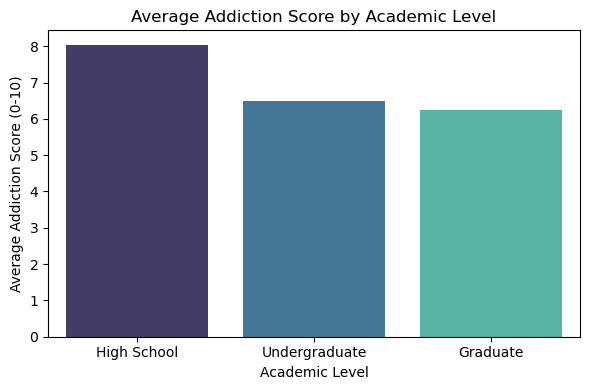

In [28]:
plt.figure(figsize=(6,4))
order = df.groupby('Academic_Level', observed=True)['Addicted_Score'].mean().sort_values(ascending=False)
sns.barplot(x=order.index, y=order.values, hue=order.index, palette='mako', legend=False)
plt.title('Average Addiction Score by Academic Level')
plt.xlabel('Academic Level')
plt.ylabel('Average Addiction Score (0-10)')
plt.tight_layout()
plt.show()

*Insight: High School students carry the heaviest addiction burden (8.0/10) — nearly two points above Graduate students — suggesting detox programs should start before university, not after.*


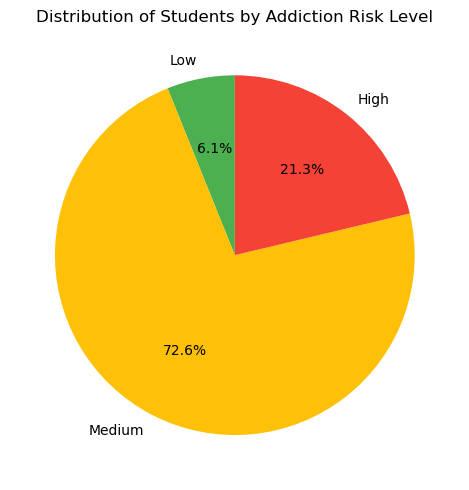

In [30]:
plt.figure(figsize=(5,5))
risk_counts = df['Risk_Level'].value_counts().reindex(['Low','Medium','High'])
plt.pie(risk_counts.values, labels=risk_counts.index, autopct='%1.1f%%',
        colors=['#4CAF50','#FFC107','#F44336'], startangle=90)
plt.title('Distribution of Students by Addiction Risk Level')
plt.tight_layout()
plt.show()

*Insight: Nearly 3 in 4 students (72.6%) already sit in the Medium-risk band — this is the group awareness campaigns can reach before they escalate to High risk (21.3%).*


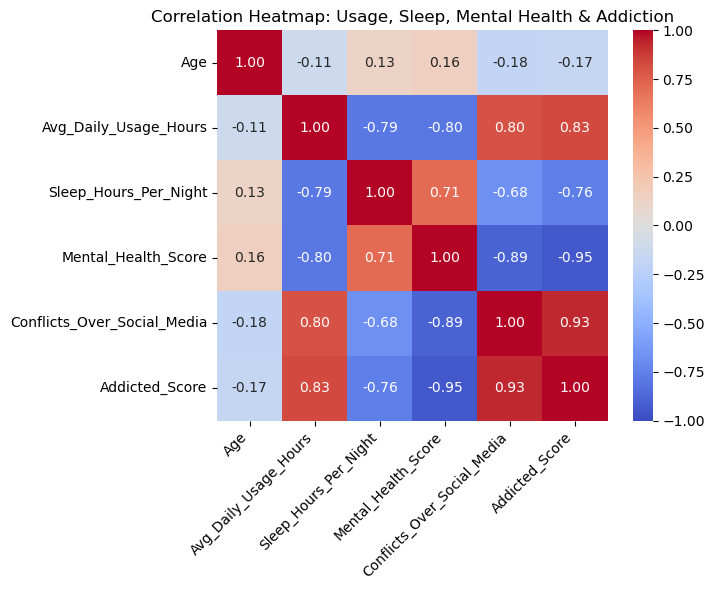

In [31]:
plt.figure(figsize=(7.5,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation Heatmap: Usage, Sleep, Mental Health & Addiction')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

*Insight: Mental health and addiction move almost perfectly opposite (r = -0.95) — addiction is not a standalone habit, it's entangled with sleep loss and declining mental wellbeing.*


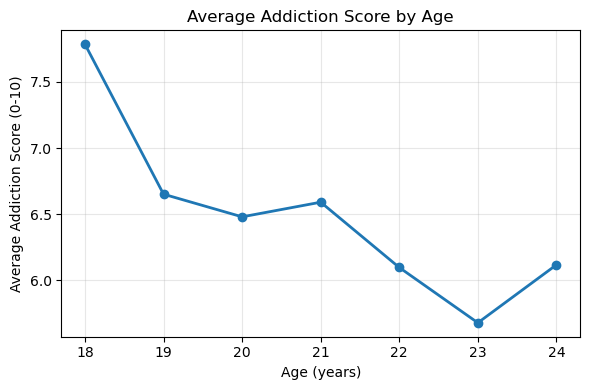

In [32]:
plt.figure(figsize=(6,4))
age_trend = df.groupby('Age')['Addicted_Score'].mean().sort_index()
plt.plot(age_trend.index, age_trend.values, marker='o', linewidth=2, color='#1f77b4')
plt.title('Average Addiction Score by Age')
plt.xlabel('Age (years)')
plt.ylabel('Average Addiction Score (0-10)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

*Insight: Addiction score trends downward with age — younger students (18-19) are consistently more addicted than older peers, reinforcing that early intervention (high school / first-year college) matters most.*


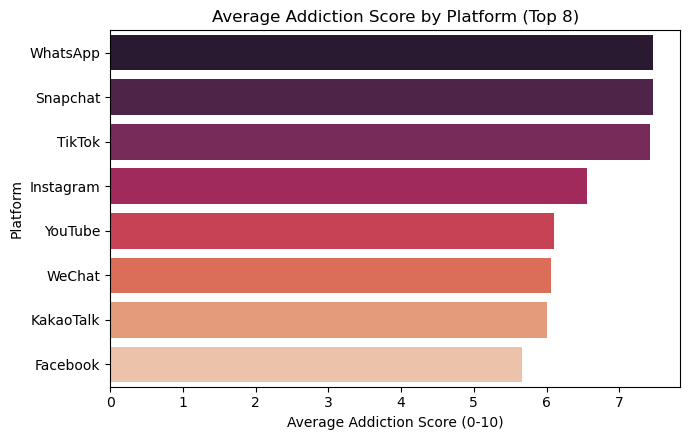

In [26]:
plt.figure(figsize=(7,4.5))
plat = df.groupby('Most_Used_Platform', observed=True)['Addicted_Score'].mean().sort_values(ascending=False).head(8)
sns.barplot(x=plat.values, y=plat.index, hue=plat.index, palette='rocket', legend=False)
plt.title('Average Addiction Score by Platform (Top 8)')
plt.xlabel('Average Addiction Score (0-10)')
plt.ylabel('Platform')
plt.tight_layout()
plt.show()

*Insight: WhatsApp, Snapchat and TikTok users show the highest average addiction scores (7.4-7.5/10) — these short-form/messaging apps warrant the most targeted messaging in a detox campaign, over LinkedIn or Facebook.*


### 6. Storytelling Deliverable
#### ● At the end of the project, craft a 10-line story summary describing:
#### ○ Key patterns
#### ○ Root causes
#### ○ Recommended actions to combat addiction

1. Across 705 students, average daily social media use sits at 4.9 hours, alongside just 6.9 hours of sleep a night.
2. Usage hours and addiction score move together almost in lockstep (r = 0.83) — more screen time is the clearest single driver of addiction risk.
3. Addiction and mental health are near-mirror opposites (r = -0.95) — the heavier the usage, the more mental wellbeing erodes.
4. Sleep pays the price too: usage and sleep are strongly negatively correlated (r = -0.79), pointing to late-night scrolling cutting into rest.
5. Conflicts over social media rise sharply with addiction (r = 0.93) — this isn't just a personal habit, it's straining relationships too.
6. 64% of students report social media actively affecting their academic performance — this is a productivity crisis, not just a wellness one.
7. High School students are the most at-risk group (8.0/10 average addiction), nearly two points above Graduate students — risk clearly declines with age and academic maturity.
8. WhatsApp, Snapchat, and TikTok users show the highest addiction scores (7.4-7.5/10), while LinkedIn users score lowest (3.8/10) — platform design and use-case matter.
9. 73% of students already sit in the "Medium risk" band (3-6 hrs/day) — this is the biggest opportunity group to reach before they slide into High risk.
10. **Recommended actions:** target awareness campaigns at younger/high-school-age students first, focus detox messaging on WhatsApp/Snapchat/TikTok specifically, and treat sleep + mental health screening as an early-warning signal for addiction — not an afterthought.